# Wine Quality Classification

## Project Objective

This project sorts red wines into good- or bad-quality groups based on their physicochemical measurements.

Wines that score 7 or 8 are considered good, while those with scores from 3 to 6 are considered bad.

The project aims to build reliable classification models for an imbalanced dataset and evaluate them using metrics that capture more than just overall accuracy.

## Import Libraries

Firstly I Loaded the libraries required for data preparation, visualisation, classification, pipelines, cross-validation and model evaluation.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## Load and Inspect the Dataset

I read the wine-quality dataset and inspect its size, quality-score distribution, missing values and duplicate rows.


In [2]:
DATA_PATH = Path("data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("Place data.csv in the same folder as this notebook.")

wine = pd.read_csv(DATA_PATH)

print(f"Rows: {len(wine):,}")
print(f"Columns: {wine.shape[1]}")
print(f"Missing values: {wine.isna().sum().sum()}")
print(f"Exact duplicate rows: {wine.duplicated().sum()}")

print("\nQuality-score distribution:")
print(wine["quality"].value_counts().sort_index())

wine.head()


Rows: 1,599
Columns: 12
Missing values: 0
Exact duplicate rows: 240

Quality-score distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Remove Exact Duplicates

Exact duplicate rows are removed before modelling to reduce the risk of identical observations appearing in both the training and test sets.


In [3]:
wine_clean = wine.drop_duplicates().reset_index(drop=True)

print(f"Rows before duplicate removal: {len(wine):,}")
print(f"Rows after duplicate removal:  {len(wine_clean):,}")
print(f"Rows removed:                 {len(wine) - len(wine_clean):,}")


Rows before duplicate removal: 1,599
Rows after duplicate removal:  1,359
Rows removed:                 240


## Create the Binary Target

Quality scores are grouped into two categories:



- 0 = Bad: quality scores from 3 to 6

- 1 = Good: quality scores from 7 to 8



The class distribution is checked since good wines make up a much smaller part of the dataset.




,count,percent
Bad (0),1175,86.5
Good (1),184,13.5


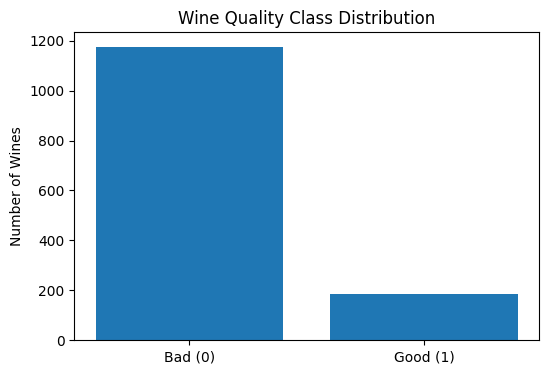

In [4]:
wine_clean["quality_class"] = (wine_clean["quality"] >= 7).astype(int)

class_summary = pd.DataFrame({
    "count": wine_clean["quality_class"].value_counts().sort_index()
})

class_summary.index = ["Bad (0)", "Good (1)"]
class_summary["percent"] = (
    class_summary["count"] / len(wine_clean) * 100
).round(1)

display(class_summary)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_summary.index, class_summary["count"])
ax.set_title("Wine Quality Class Distribution")
ax.set_ylabel("Number of Wines")
plt.show()


## Prepare Features and Split the Data

The original quality score is excluded from the predictors because it is used to construct the target variable.



A stratified train/test split keeps the class proportions the same in both the training and test sets.


In [ ]:
X = wine_clean.drop(columns=["quality", "quality_class"])
y = wine_clean["quality_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))


Training rows: 1087
Test rows: 272

Training class proportions:
quality_class
0    0.865
1    0.135
Name: proportion, dtype: float64

Test class proportions:
quality_class
0    0.864
1    0.136
Name: proportion, dtype: float64


## Build a Baseline Model

I used `DummyClassifier` as a simple benchmark.

Since the dataset is imbalanced, simply predicting the majority class can still result in high overall accuracy. This gives a helpful baseline for evaluating the machine-learning models.


In [6]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)


## Train a Random Forest

A Random Forest classifier is trained with class balancing so that errors on the minority good-wine class receive greater importance.


In [7]:
rf = RandomForestClassifier(
    n_estimators=400,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)


## Tune a Support Vector Machine

I placed SVM model inside a `Pipeline` with `StandardScaler`.

This ensured scaling is performed correctly inside each cross-validation fold and prevents information from the validation data leaking into model training.

`GridSearchCV` is optimised using the F1 score for the good-wine class.


In [8]:
svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(class_weight="balanced"))
])

param_grid = {
    "svc__C": [0.1, 0.5, 1, 2, 5, 10],
    "svc__kernel": ["rbf"],
    "svc__gamma": ["scale", 0.01, 0.05, 0.1, 0.2]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_svc = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1
)

grid_svc.fit(X_train, y_train)

best_svc = grid_svc.best_estimator_
svc_pred = best_svc.predict(X_test)

print("Best SVM parameters:", grid_svc.best_params_)
print(f"Best cross-validation F1: {grid_svc.best_score_:.3f}")


Best SVM parameters: {'svc__C': 2, 'svc__gamma': 0.05, 'svc__kernel': 'rbf'}
Best cross-validation F1: 0.518


## Compare Model Performance

The models are compared using several metrics:

- Accuracy — overall percentage of correct predictions.
- Balanced Accuracy — gives equal importance to both classes.
- Precision (Good) — how many predicted good wines were actually good.
- Recall (Good) — how many actual good wines were correctly identified.
- F1 (Good)— balances precision and recall for the minority class.


In [9]:
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision (Good)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Good)": recall_score(y_true, y_pred, zero_division=0),
        "F1 (Good)": f1_score(y_true, y_pred, zero_division=0)
    }

comparison = pd.DataFrame([
    evaluate_model("Dummy Baseline", y_test, dummy_pred),
    evaluate_model("Random Forest", y_test, rf_pred),
    evaluate_model("Tuned SVM", y_test, svc_pred)
]).set_index("Model")

comparison.round(3)


,Accuracy,Balanced Accuracy,Precision (Good),Recall (Good),F1 (Good)
Model,,,,,
Dummy Baseline,0.864,0.500,0.000,0.000,0.000
Random Forest,0.882,0.681,0.600,0.405,0.484
Tuned SVM,0.798,0.792,0.382,0.784,0.513


## Evaluate the Tuned SVM

The tuned SVM is inspected in more detail using a classification report and confusion matrix.


              precision    recall  f1-score   support

         Bad       0.96      0.80      0.87       235
        Good       0.38      0.78      0.51        37

    accuracy                           0.80       272
   macro avg       0.67      0.79      0.69       272
weighted avg       0.88      0.80      0.82       272



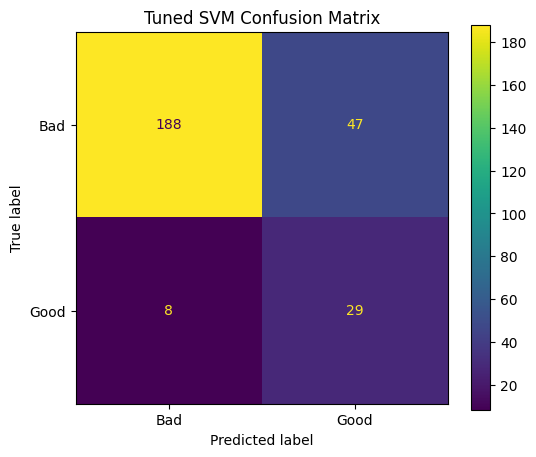

In [10]:
print(classification_report(
    y_test,
    svc_pred,
    target_names=["Bad", "Good"],
    zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    svc_pred,
    display_labels=["Bad", "Good"],
    ax=ax
)

ax.set_title("Tuned SVM Confusion Matrix")
plt.show()


## Evaluate the Random Forest

The Random Forest confusion matrix is used to compare its error pattern with the tuned SVM.


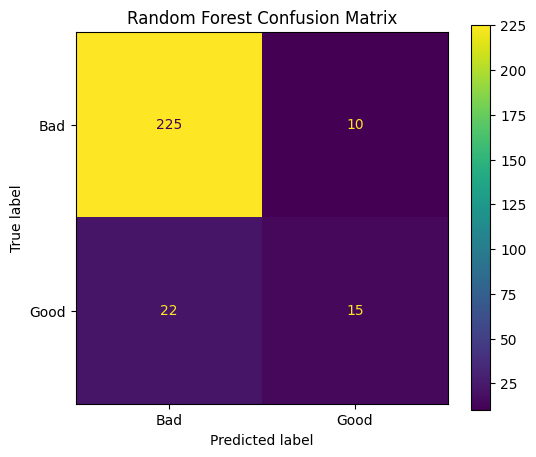

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Bad", "Good"],
    ax=ax
)

ax.set_title("Random Forest Confusion Matrix")
plt.show()


## Analyse Feature Importance

Random Forest feature importance helps show which physicochemical variables have the greatest impact on the model's classification decisions.

Feature importance shows how the model behaves, but it does not prove that one variable causes another.


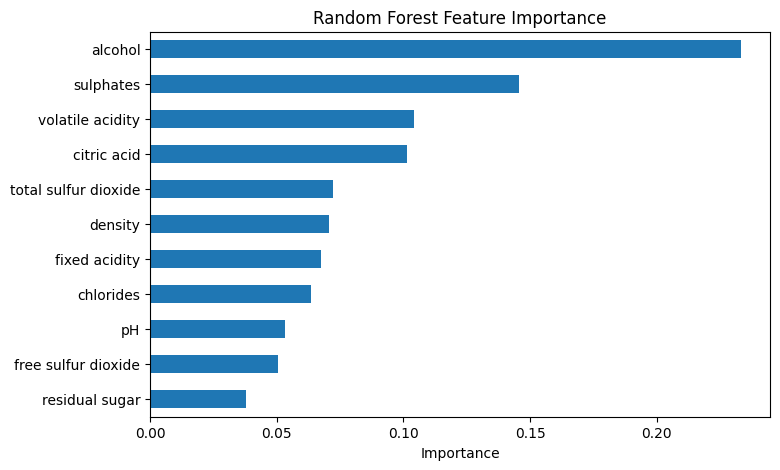

,importance
alcohol,0.233
sulphates,0.146
volatile acidity,0.104
citric acid,0.101
total sulfur dioxide,0.072
density,0.071
fixed acidity,0.068
chlorides,0.063
pH,0.053
free sulfur dioxide,0.051


In [12]:
feature_importance = (
    pd.Series(rf.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))

feature_importance.sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Importance")
plt.show()

feature_importance.to_frame("importance").round(3)


## Key Findings

The dataset is highly imbalanced, which means that looking at overall accuracy by itself does not fully show how well the model performs.

The Dummy baseline gets high accuracy because it always predicts the majority class, but it does not find any good wines.

Random Forest has the highest overall accuracy. However, the tuned SVM finds a much larger share of the minority good-wine class and gives more balanced results.

This shows an important principle in modeling:

The model with the highest overall accuracy is not always the best choice for an imbalanced classification problem.

For this task, recall, F1, and balanced accuracy give a better picture of model quality than accuracy alone.



## Skills Demonstrated

- Data cleaning and validation
- Duplicate handling
- Binary classification
- Imbalanced-data evaluation
- Stratified train/test splitting
- Random Forest
- Support Vector Machines
- Scikit-learn Pipelines
- Feature scaling
- GridSearchCV
- Cross-validation
- Confusion-matrix analysis
- Feature importance
- Critical model interpretation
